# Tugas Praktikum


Import library


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hdbscan

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


Muat dataset dan memisahkan fitur dari label


In [2]:
df = pd.read_csv("burnout_dataset1.csv")
df.fillna(df.mean(numeric_only=True), inplace=True)

# Mengambil sampel representatif untuk clustering HDBSCAN
df_sample = df.sample(n=1000, random_state=42)

feature_columns = [
    "Work_Hours_Per_Week",
    "Job_Satisfaction",
    "Work_Life_Balance",
    "Burnout_Score",
]

X = df_sample[feature_columns].to_numpy()
risk = df_sample["Burnout_Risk"].to_numpy()

display(df_sample[feature_columns + ["Burnout_Risk"]].head())


,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Burnout_Score,Burnout_Risk
33553,58,8.0,9.0,52,Moderate
9427,53,1.0,8.0,42,Moderate
199,59,3.0,2.0,46,Moderate
12447,49,9.0,8.0,58,Moderate
39489,39,3.0,9.0,50,Moderate


Standardisasi Fitur


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


Menjalankan HDBSCAN dan menghitung hasilnya


In [4]:
model = hdbscan.HDBSCAN(
    min_cluster_size=15,
    min_samples=5,
    metric="euclidean",
)

labels = model.fit_predict(X_scaled)

n_clusters = len(set(labels) - {-1})
n_noise = np.sum(labels == -1)

print("Jumlah cluster:", n_clusters)
print("Jumlah noise:", n_noise)
print(f"Persentase noise: {n_noise / len(labels) * 100:.2f}%")

display(
    pd.Series(labels, name="Cluster")
    .value_counts()
    .sort_index()
    .rename("Jumlah anggota")
    .to_frame()
)


Jumlah cluster: 3
Jumlah noise: 709
Persentase noise: 70.90%


,Jumlah anggota
Cluster,
-1,709
0,70
1,175
2,46


Visualisasi dengan PCA


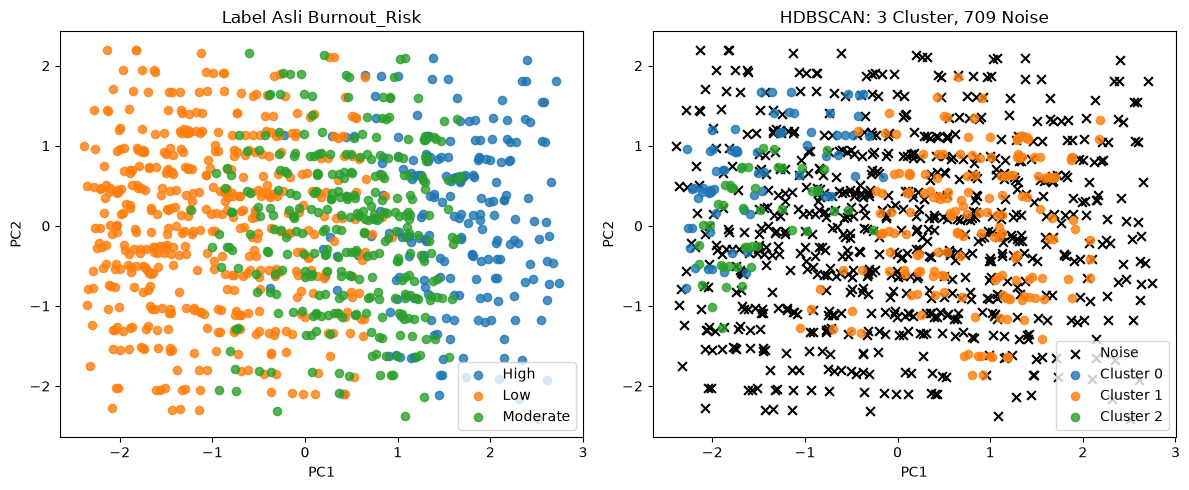

Variansi yang dijelaskan oleh dua komponen PCA: 66.28%


In [5]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Grafik label asli
for name in np.unique(risk):
    mask = risk == name
    axes[0].scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        label=name, s=35, alpha=0.8
    )

axes[0].set_title("Label Asli Burnout_Risk")

for label in np.unique(labels):
    mask = labels == label

    if label == -1:
        axes[1].scatter(
            X_pca[mask, 0], X_pca[mask, 1],
            color="black", marker="x", label="Noise", s=40
        )
    else:
        axes[1].scatter(
            X_pca[mask, 0], X_pca[mask, 1],
            label=f"Cluster {label}", s=35, alpha=0.8
        )

axes[1].set_title(
    f"HDBSCAN: {n_clusters} Cluster, {n_noise} Noise"
)

for ax in axes:
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend()

plt.tight_layout()
plt.show()

print(
    "Variansi yang dijelaskan oleh dua komponen PCA:",
    f"{pca.explained_variance_ratio_.sum():.2%}"
)


Membandingkan cluster dengan label asli


In [6]:
comparison = pd.crosstab(
    pd.Series(risk, name="Risiko Burnout asli"),
    pd.Series(labels, name="Cluster"),
)

display(comparison)


Cluster,-1,0,1,2
Risiko Burnout asli,,,,
High,163,0,48,0
Low,336,69,33,45
Moderate,210,1,94,1


Analisis Berdasarkan Output Kode Program

Berdasarkan output notebook, HDBSCAN dengan min_cluster_size=15 dan min_samples=5 menghasilkan 3 klaster kepadatan dan 709 data yang dikategorikan sebagai noise dari 1000 data sampel.

Hasil klasterisasi menunjukkan bagaimana algoritma berbasis kepadatan mengidentifikasi kelompok pekerja dengan karakteristik beban kerja dan tingkat kejenuhan yang sangat padat. Cluster 0 didominasi oleh pekerja dengan risiko burnout rendah (Low), Cluster 1 mencakup kombinasi pekerja dengan tingkat risiko burnout sedang hingga tinggi (Moderate dan High), sedangkan Cluster 2 mewakili kelompok pekerja dengan risiko rendah yang terkonsentrasi di area fitur tertentu.

Data yang ditetapkan sebagai noise (-1) menunjukkan individu-individu dengan pola kerja atau kombinasi skor yang tersebar dan berada di area berkerapatan rendah, yang sering kali mencerminkan variasi individual dalam respons terhadap beban kerja.

Dua komponen utama PCA berhasil mempertahankan variansi data yang signifikan dari fitur-fitur kerja dan burnout, sehingga visualisasi 2 dimensi dapat menggambarkan pemisahan ruang data dengan baik.
